In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "dataset_bambu_multi_printer.csv",
    sep=",",
    engine="python",
    on_bad_lines="skip"
)

sns.set_theme(style="whitegrid")

# Conversión de timestamp
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Inspección de valores nulos (246 registros faltantes en gcode_state y mc_print_stage)
print("Nulos por columna:\n", df.isnull().sum())

Nulos por columna:
 timestamp            0
printer_name         0
serial_number        0
gcode_state        246
mc_print_stage     246
tray_type            0
mc_percent           0
layer_num            0
total_layer_num      0
nozzle_temp          0
bed_temp             0
dtype: int64


In [5]:
# Promedio, mínimo y máximo de temperatura por tipo de bandeja
perfil_termico = df.groupby('tray_type')[['nozzle_temp', 'bed_temp']].agg(['mean', 'min', 'max'])
print(perfil_termico)

# Detectar impresoras funcionando con temperaturas inusualmente altas o bajas
anomalias_temp = df[(df['nozzle_temp'] > 260) | (df['nozzle_temp'] < 180)]

            nozzle_temp               bed_temp           
                   mean  min    max       mean  min   max
tray_type                                                
Desconocido   73.608454  0.0  223.0  36.824448  0.0  55.0
PLA          175.756319  0.0  242.0  52.444180  0.0  55.0


In [8]:
# Actividad por día de la semana u hora
df['hora'] = df['timestamp'].dt.hour
df['dia_semana'] = df['timestamp'].dt.day_name()

# Volumen de registros por hora del día
actividad_por_hora = df.groupby('hora').size()

# Duración estimada por sesión de trabajo (diferencia entre primer y último timestamp)
duracion_sesion = df.groupby(['printer_name', 'total_layer_num'])['timestamp'].agg(lambda x: x.max() - x.min())

C:\Users\udaet\AppData\Local\Temp\ipykernel_23904\323326550.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='gcode_state', palette='viridis')


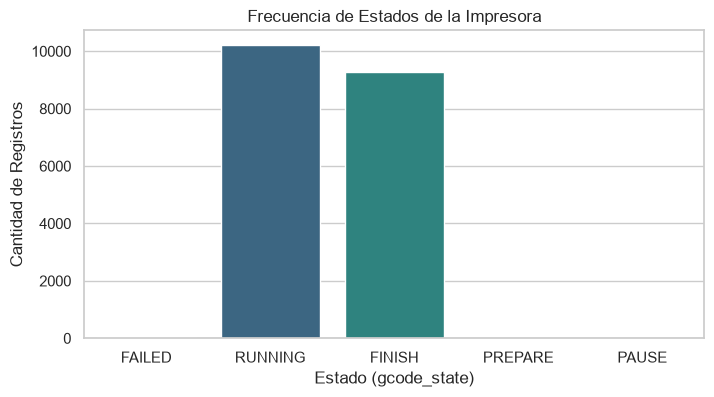

In [11]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='gcode_state', palette='viridis')
plt.title('Frecuencia de Estados de la Impresora')
plt.xlabel('Estado (gcode_state)')
plt.ylabel('Cantidad de Registros')
plt.show()

C:\Users\udaet\AppData\Local\Temp\ipykernel_23904\2961793310.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='tray_type', y='nozzle_temp', palette='Set2')


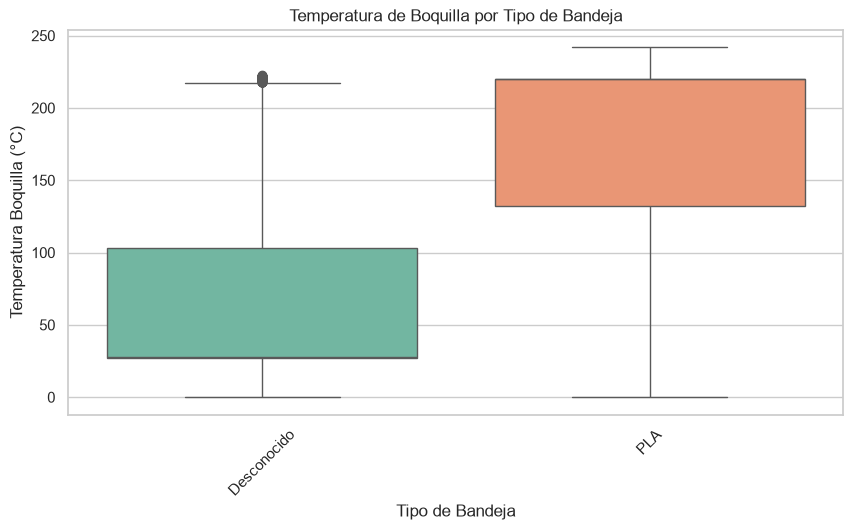

In [12]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='tray_type', y='nozzle_temp', palette='Set2')
plt.title('Temperatura de Boquilla por Tipo de Bandeja')
plt.xlabel('Tipo de Bandeja')
plt.ylabel('Temperatura Boquilla (°C)')
plt.xticks(rotation=45)
plt.show()

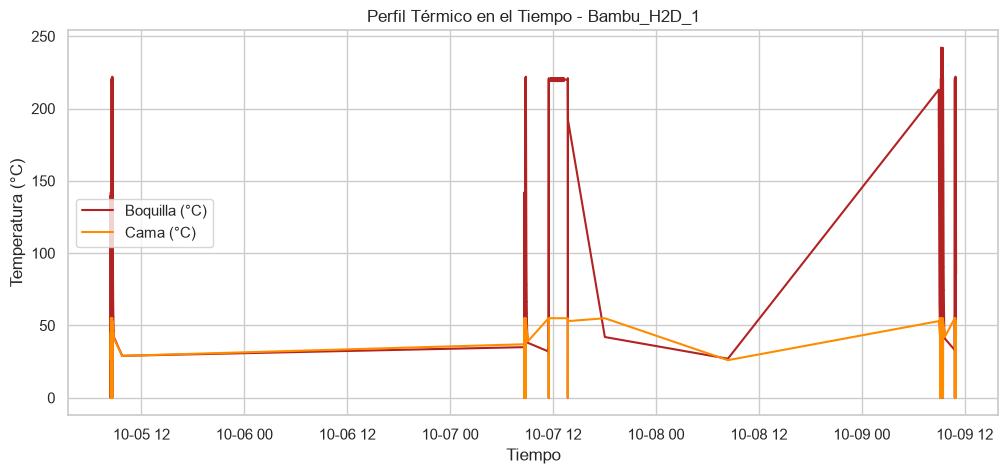

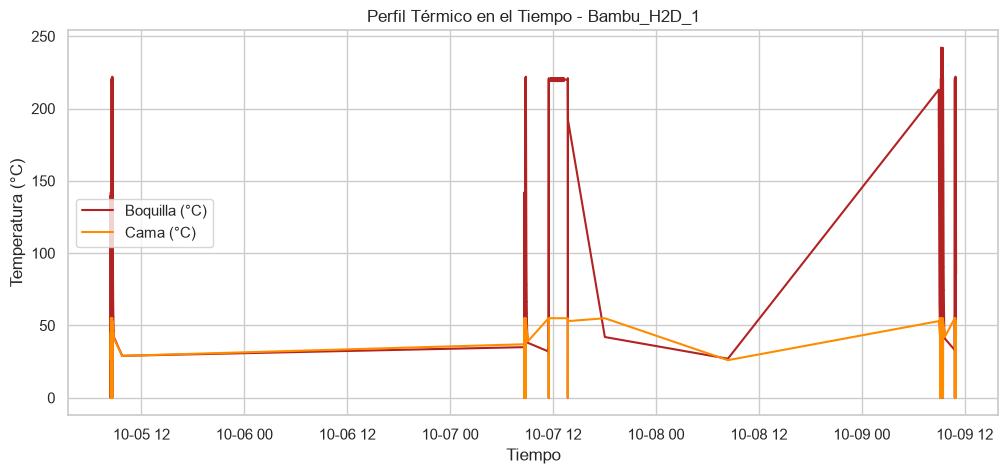

In [13]:
# Filtrar por una impresora específica para no saturar la gráfica
impresora_1 = df[df['printer_name'] == df['printer_name'].iloc[0]].sort_values('timestamp')

plt.figure(figsize=(12, 5))
plt.plot(impresora_1['timestamp'], impresora_1['nozzle_temp'], label='Boquilla (°C)', color='firebrick')
plt.plot(impresora_1['timestamp'], impresora_1['bed_temp'], label='Cama (°C)', color='darkorange')

plt.title(f'Perfil Térmico en el Tiempo - {impresora_1["printer_name"].iloc[0]}')
plt.xlabel('Tiempo')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.show()# Filtrar por una impresora específica para no saturar la gráfica
impresora_1 = df[df['printer_name'] == df['printer_name'].iloc[0]].sort_values('timestamp')

plt.figure(figsize=(12, 5))
plt.plot(impresora_1['timestamp'], impresora_1['nozzle_temp'], label='Boquilla (°C)', color='firebrick')
plt.plot(impresora_1['timestamp'], impresora_1['bed_temp'], label='Cama (°C)', color='darkorange')

plt.title(f'Perfil Térmico en el Tiempo - {impresora_1["printer_name"].iloc[0]}')
plt.xlabel('Tiempo')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.show()

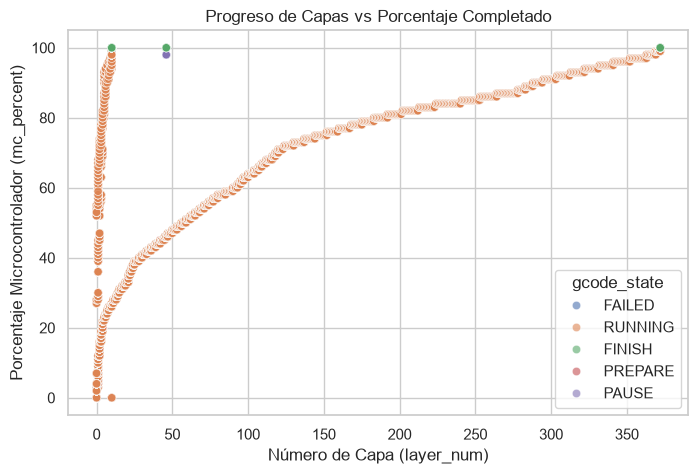

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='layer_num', y='mc_percent', hue='gcode_state', alpha=0.6)
plt.title('Progreso de Capas vs Porcentaje Completado')
plt.xlabel('Número de Capa (layer_num)')
plt.ylabel('Porcentaje Microcontrolador (mc_percent)')
plt.show()

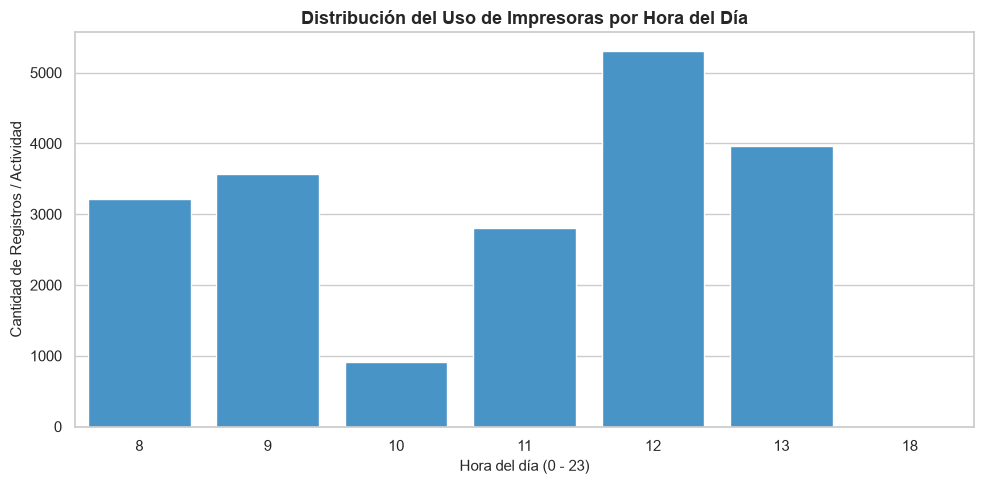

In [15]:
df['hora'] = df['timestamp'].dt.hour

# Configuración del estilo
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Gráfico de barras por hora del día
sns.countplot(data=df, x='hora', color='#3498db')

plt.title('Distribución del Uso de Impresoras por Hora del Día', fontsize=13, fontweight='bold')
plt.xlabel('Hora del día (0 - 23)', fontsize=11)
plt.ylabel('Cantidad de Registros / Actividad', fontsize=11)

plt.tight_layout()
plt.show()

C:\Users\udaet\AppData\Local\Temp\ipykernel_23904\2242288781.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=uso_por_impresora.values, y=uso_por_impresora.index, palette='Blues_r')


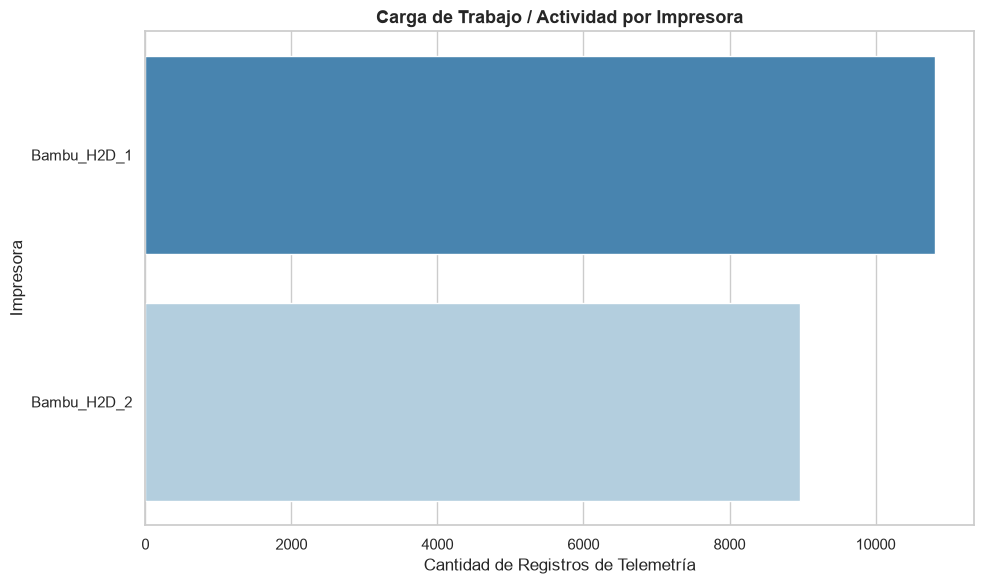

In [16]:
plt.figure(figsize=(10, 6))
uso_por_impresora = df['printer_name'].value_counts()

sns.barplot(x=uso_por_impresora.values, y=uso_por_impresora.index, palette='Blues_r')
plt.title('Carga de Trabajo / Actividad por Impresora', fontsize=13, fontweight='bold')
plt.xlabel('Cantidad de Registros de Telemetría')
plt.ylabel('Impresora')
plt.tight_layout()
plt.show()

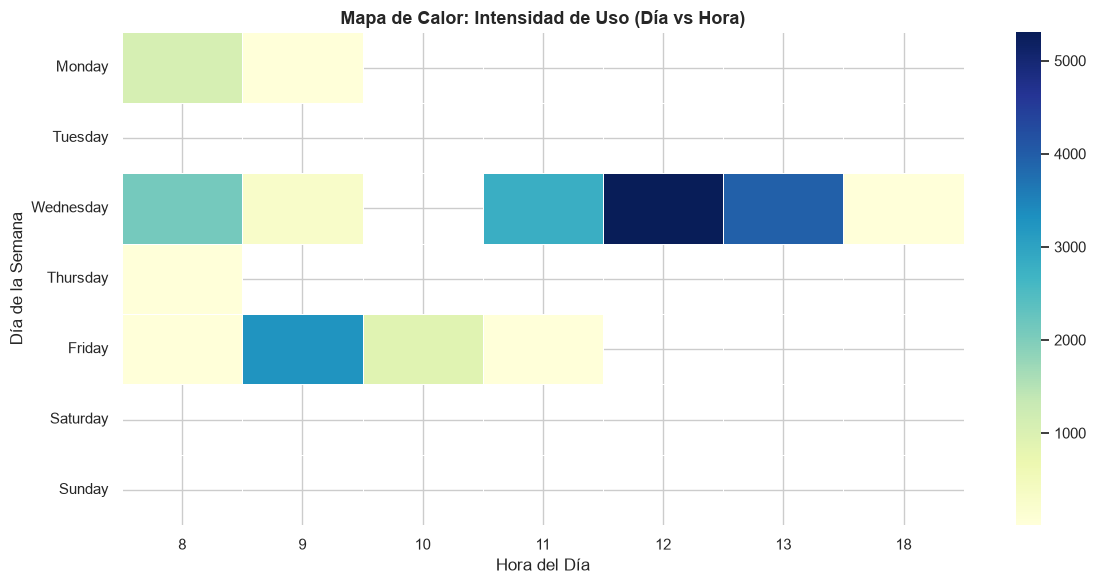

In [17]:
# Preparar datos de día de la semana u hora
df['dia_semana'] = df['timestamp'].dt.day_name()
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Crear tabla pivote
matriz_actividad = df.pivot_table(index='dia_semana', columns='hora', values='serial_number', aggfunc='count').reindex(dias_orden)

plt.figure(figsize=(12, 6))
sns.heatmap(matriz_actividad, cmap='YlGnBu', linewidths=0.5, annot=False)
plt.title('Mapa de Calor: Intensidad de Uso (Día vs Hora)', fontsize=13, fontweight='bold')
plt.xlabel('Hora del Día')
plt.ylabel('Día de la Semana')
plt.tight_layout()
plt.show()

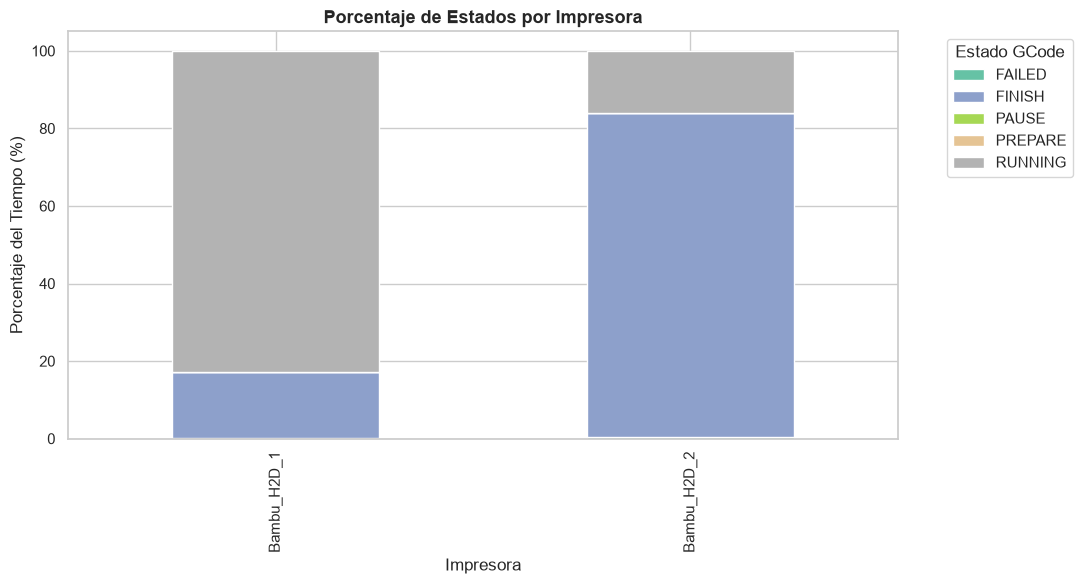

In [18]:
# Crear tabla de frecuencias relativas (porcentaje por impresora)
estados_por_impresora = pd.crosstab(df['printer_name'], df['gcode_state'], normalize='index') * 100

ax = estados_por_impresora.plot(kind='bar', stacked=True, figsize=(11, 6), colormap='Set2')
plt.title('Porcentaje de Estados por Impresora', fontsize=13, fontweight='bold')
plt.xlabel('Impresora')
plt.ylabel('Porcentaje del Tiempo (%)')
plt.legend(title='Estado GCode', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

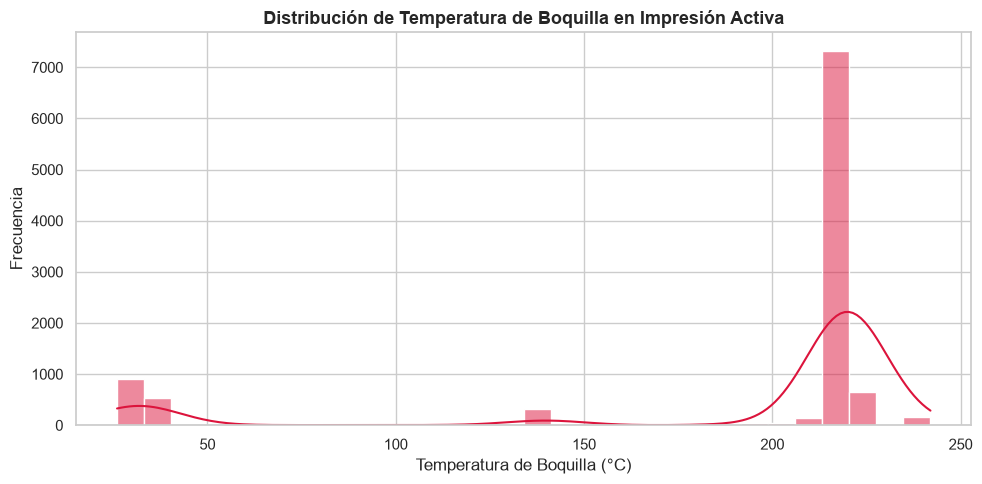

In [19]:
# Filtrar registros en estado de impresión
imprimiendo = df[df['gcode_state'] == 'RUNNING'] if 'RUNNING' in df['gcode_state'].values else df

plt.figure(figsize=(10, 5))
sns.histplot(data=imprimiendo, x='nozzle_temp', kde=True, color='crimson', bins=30)
plt.title('Distribución de Temperatura de Boquilla en Impresión Activa', fontsize=13, fontweight='bold')
plt.xlabel('Temperatura de Boquilla (°C)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()